In [ ]:
import torch.utils.data
from hydra import initialize, compose
from omegaconf import DictConfig
import os

from sentence_transformers.util import similarity

from src.data.dataloader import data_loader
from src.data.dataset_aprdb import AprdbDataset

import src.config
from src.detector.cristal_anchor.fetch_academic_paper import extract_text_from_pdf

with initialize(version_base=None, config_path="../conf"):
    cfg: DictConfig = compose(config_name="config",overrides=["+experiment/dataset/aprbd@dataset=aprdb_tt_test_all","experiment/data_loader=1_4_true"])

os.environ['CUDA_LAUNCH_BLOCKING'] = "1"
MODEL_NAME = "qwen3-14b"

print(cfg)

In [ ]:
ds_test = AprdbDataset(config=cfg.dataset)
len(ds_test)

### getting dataframe conversion

In [ ]:
import pandas as pd
rows = []
for i in range(len(ds_test)):
    item = ds_test[i]
    rows.append(item)
df = pd.DataFrame(rows)
df.dropna(subset=['forum_id'], inplace=True)
df

## Filter for the databse

In [ ]:
year = "2019"
conference = "ICLR"
generator = "qwen"
mgt_df = df[(df.label == 1) & (df['conference'] == conference) & (df['year'] == year) & (df['generator'] == generator)]

hwt_df = df[(df.label == 0) & (df.conference == conference) & (df.year == year)]
mgt_df

In [ ]:
sampled = pd.concat([
    mgt_df.sample(n=25, random_state=42),
    hwt_df.sample(n=25, random_state=42)
])

In [ ]:
from datasets import Dataset as HFDataset
dataloader = data_loader(
    cfg.experiment.data_loader,
    HFDataset.from_pandas(sampled, preserve_index=False),
)

In [ ]:
random_batch = next(iter(dataloader))
batch_id = random_batch['review-id']
print(random_batch)
print("---------------------------")
print(batch_id, random_batch['content'][0])



# reverse Prompt Engineering

In [ ]:
txt = random_batch['content']
from src.detector.cristal_anchor.fetch_academic_paper import extract_text_from_pdf
paper = extract_text_from_pdf(random_batch['pdf_path'][0])

In [ ]:
REVIEW_OUTPUT_SPEC = """

Return your answer in the following exact structure, using these literal markers:

<RECONSTRUCTED_SYSTEM_PROMPT>
[the system prompt here]
</RECONSTRUCTED_SYSTEM_PROMPT>

<RECONSTRUCTED_USER_PROMPT>
[the user prompt here, with a {paper} placeholder where the paper content should be injected]
</RECONSTRUCTED_USER_PROMPT>

<JUSTIFICATION>
[phase 4 content]
</JUSTIFICATION>

<FALSIFICATION>
[phase 5 content]
</FALSIFICATION>
"""

In [ ]:
REVIEW_OUTPUT_SPEC_2 = """

Return your answer in the following exact structure, using these literal markers.

The reconstructed prompts MUST be self-contained: a third party reading only
<RECONSTRUCTED_SYSTEM_PROMPT> + <RECONSTRUCTED_USER_PROMPT> + an arbitrary paper
must be able to regenerate a text isomorphic to the target.

<RECONSTRUCTED_SYSTEM_PROMPT>
Must crystallize the following invariants from Phase 1/2:
- PERSONA: assigned role, expertise level, viewpoint (I2)
- REGISTER & STYLE: lexical field, hedging frequency, syntactic patterns (I3, I4)
- FORMATTING RULES: Markdown usage, citation style, typography (I5)
- TONE CONSTRAINTS: imposed stance, modality (I7)
- LLM-specific stylistic directives (I8) if detected

Write as a coherent role description, NOT as a bullet list of invariants.
Do NOT mention the paper, sections, or task-specific instructions here.
</RECONSTRUCTED_SYSTEM_PROMPT>

<RECONSTRUCTED_USER_PROMPT>
Must crystallize:
- TASK STATEMENT: the direct instruction inferred in Phase 2
- MANDATORY SECTIONS with ordering (I1) — list them explicitly
- EVALUATION CRITERIA with their weighting (I6)
- LENGTH DIRECTIVE: explicit word target based on the analyse of the based review(I9)
- The literal placeholder {paper} where the input paper must be injected

Write as an executable instruction. End with the {paper} block.
</RECONSTRUCTED_USER_PROMPT>

<MAPPING_TABLE>
Two-column table showing where each Phase 1 invariant (I1..I9) and each Phase 2
deduction was placed (SYSTEM | USER | OMITTED) with a one-line justification.
Any invariant marked OMITTED must justify why it was not actionable.
</MAPPING_TABLE>

<JUSTIFICATION>
For each non-trivial choice in SYSTEM and USER prompts, cite the textual evidence
(short quote from target) that motivates it. Format: "[quote] → [prompt element]".
</JUSTIFICATION>

<FALSIFICATION>
3 alternative reconstructions and why they are rejected.
Residual ambiguities requiring empirical iteration.
</FALSIFICATION>"""

In [ ]:
def build_prompt(txt, review_spec):
    return f"""# ROLE
You are an expert in reverse prompt engineering, specialized in retro-engineering prompts from LLM outputs. Your goal: reconstruct the prompt that most likely generated a given target text, such that re-executing this prompt produces an output stylistically and structurally isomorphic to the target.


# INPUT
<TARGET_TEXT>
{txt}
</TARGET_TEXT>

# METHODOLOGY (execute explicitly, step by step)

## Phase 1 — Forensic analysis of the target text
Extract and document the following invariants:

1. **Macro-structure**: sections, ordering, hierarchy, transitions, relative length of each block.
2. **Implicit persona**: displayed expertise level, stance (critical/supportive/neutral), domain, viewpoint (NeurIPS/ICML/ACL reviewer? editor? naive reader?).
3. **Lexical register**: dominant semantic field, technical terminology, frequency of hedges ("arguably", "it seems"), recurring logical connectors.
4. **Syntactic patterns**: average sentence length, passive/active voice ratio, first-person usage, modalities.
5. **Formatting conventions**: Markdown usage, presence of lists, citations, formulas, typography (italics for technical terms?).
6. **Evaluation axes**: which criteria does the text judge on (originality, soundness, clarity, significance, reproducibility)? With what apparent weighting?
7. **Implicit constraints**: length limits, mandatory sections, imposed tone (cf. conference reviewer guidelines such as NeurIPS).
8. **LLM-specific signals** (if relevant): tell-tale phrasings of specific models (GPT-4, Claude, Gemini), stylistic tics, canonical formulas.
9. **size** : the size is close to {len(str(txt).split())} words long.

## Phase 2 — Inference of latent parameters
Deduce:
- The probable **system prompt** (assigned role, format constraints).
- The probable **user prompt** (direct instruction, provided context, requirements, size of the target based on the text).
- Possible **few-shot examples** (does the text follow a visible template?).
- Plausible **generation parameters** (low/high temperature based on observed creativity).

## Phase 3 — Synthesis of the candidate prompt
Produce the reconstructed prompt respecting:
- The **language** of the target text (English).
- A directly executable format (system + user).
- A specification sufficiently **constraining** to reproduce the structure, yet sufficiently **generalizable** to work on a different paper as input.
- Explicit inclusion of sections, tone, criteria, and any detected length constraints.

## Phase 4 — Line-by-line justification
For each element of the reconstructed prompt, indicate as a comment the textual evidence (short quote from the target text) motivating that choice.

## Phase 5 — Falsification test
List 3 alternative hypotheses about the source prompt and explain why you reject them. Identify residual ambiguities that only empirical iteration could resolve.

# OUTPUT (strict format)""" + review_spec


In [ ]:
import re

from openai import OpenAI

VLLM_API_BASE = "http://127.0.0.1:8000/v1"
_client = OpenAI(base_url=VLLM_API_BASE, api_key="EMPTY")

def chat(messages, *, enable_thinking=False, temperature=0.7, top_p=0.95,
         top_k=20, max_tokens=2048):
    if enable_thinking and temperature > 0.6:
        temperature = 0.6
    resp = _client.chat.completions.create(
        model=MODEL_NAME,
        messages=messages,
        temperature=temperature,
        top_p=top_p,
        max_tokens=max_tokens,
        extra_body={
            "top_k": top_k,
            "chat_template_kwargs": {"enable_thinking": enable_thinking},
        },
    )
    msg = resp.choices[0].message
    return {
        "content": (msg.content or "").strip(),
        "reasoning": getattr(msg, "reasoning_content", None),
        "finish_reason": resp.choices[0].finish_reason,
        "usage": dict(resp.usage),
    }

def _extract_tag(text: str, tag: str, required: bool = True) -> str | None:
    """Extrait le contenu d'un tag. Si non requis et absent, renvoie None."""
    m = re.search(rf"<{tag}>(.*?)</{tag}>", text, flags=re.DOTALL)
    if not m:
        # Fallback : tag ouvert mais pas refermé (sortie tronquée)
        m_open = re.search(rf"<{tag}>(.*)", text, flags=re.DOTALL)
        if m_open and not required:
            return m_open.group(1).strip()
        if required:
            raise ValueError(f"Required tag <{tag}> not found in output")
        return None
    return m.group(1).strip()

def reverse_engineer_prompt(review_text: str) -> dict:
    """Étape 1 : extrait system_prompt + user_prompt depuis une review."""
    out = chat(
        [{"role": "user", "content": build_prompt(review_text, REVIEW_OUTPUT_SPEC_2)}],
        enable_thinking=True,
        temperature=0.6,
        max_tokens=20000,
    )
    raw = out["content"]

    if out.get("finish_reason") == "length":
        print(f"[WARN] Reverse-engineering output truncated "
              f"(usage: {out['usage']})")
    return {
        "system_prompt": _extract_tag(raw, "RECONSTRUCTED_SYSTEM_PROMPT"),
        "user_prompt_template": _extract_tag(raw, "RECONSTRUCTED_USER_PROMPT"),
        "justification": _extract_tag(raw, "JUSTIFICATION", required=False),
        "falsification": _extract_tag(raw, "FALSIFICATION", required=False),
        "raw": raw,
        "usage": out["usage"],
        "reasoning": out["reasoning"],
    }



def generate_review(paper: str, reconstructed: dict,
                    enable_thinking: bool = False,
                    temperature: float = 0.7,
                    max_tokens: int = 4096,
                    top_p: float = 0.95,
                    top_k: int = 20) -> dict:
    """Étape 2 : applique le prompt reconstruit au papier cible."""
    if "{paper}" not in reconstructed["user_prompt_template"]:
        # fallback si le modèle a oublié le placeholder
        user_content = reconstructed["user_prompt_template"] + f"\n\n<PAPER>\n{paper}\n</PAPER>"
    else:
        user_content = reconstructed["user_prompt_template"].replace("{paper}", paper)



    return chat(
        [
            {"role": "system", "content": reconstructed["system_prompt"]},
            {"role": "user", "content": user_content},
        ],
        enable_thinking=enable_thinking,
        temperature=temperature,
        max_tokens=max_tokens,
        top_p=top_p,
        top_k=top_k
    )


def review_pipeline(review_ref: str, paper_text: str) -> dict:
    max_token = 4093
    reconstructed = reverse_engineer_prompt(review_ref)
    generated = generate_review(paper_text, reconstructed, max_tokens=max_token, enable_thinking=False)
    return {
        "reconstructed": reconstructed,
        "generated_review": generated["content"],
        "generated_reasoning": generated["reasoning"],
        "usage": {
            "reverse": reconstructed["usage"],
            "generate": generated["usage"],
        },
    }



In [ ]:
# === Test ===
r = random_batch["content"][0] if isinstance(random_batch["content"], list) else random_batch["content"]
p = extract_text_from_pdf(random_batch["pdf_path"][0])



In [ ]:
result = review_pipeline(r, p)

In [ ]:
print("=== RECONSTRUCTED SYSTEM ===")
print(result["reconstructed"]["system_prompt"])
print("\n=== RECONSTRUCTED USER (template) ===")
print(result["reconstructed"]["user_prompt_template"])
print("\n=== GENERATED REVIEW ===")
print(result["generated_review"], len(result["generated_review"]))
print("\n=== REASONING ===")
print(result["reconstructed"]["reasoning"])
print("\n=== GENERATED REVIEW ===")
print("\n=== USAGE ===")
print(result["usage"])
result_review = result['generated_review']

In [ ]:
print(str(random_batch['content'][0]), f"\n----------------- END -------------------\n",str(result_review))
print(len(random_batch['content'][0].split()), len(str(result_review).split()))

In [9]:
from sentence_transformers import SentenceTransformer
embedding_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

Loading weights: 100%|██████████| 103/103 [00:02<00:00, 38.88it/s]


In [ ]:
## test embedding
embedded_target = embedding_model.encode(random_batch["content"][0])
embedded_generated_review = embedding_model.encode(result_review)

similarity = embedding_model.similarity(embedded_target, embedded_generated_review)
print(similarity)

In [ ]:
from datasets import tqdm
label = []
target = []
infos = []
errors = 0
for batch in tqdm(dataloader):
    try:
        r = batch["content"][0] if isinstance(batch["content"], list) else batch["content"]
        p = extract_text_from_pdf(batch["pdf_path"][0])

        result = review_pipeline(r, p)
        result_review = result['generated_review']

        embedded_target = embedding_model.encode(random_batch["content"][0])
        embedded_generated_review = embedding_model.encode(result_review)

        similarity = embedding_model.similarity(embedded_target, embedded_generated_review)

        infos.append({
            "label" : batch['label'],
            "target_review" : r,
            "generated_review" : result_review,
            "similarity" : similarity,
            "system_prompt" : result["reconstructed"]["system_prompt"],
            "usage": result["usage"],
            "user_prompt_template": result["reconstructed"]["user_prompt_template"],
            "paper_id": batch['forum_id'],
            "review-id": batch['review-id'],
            "conference": batch['conference'],
            "year": batch['year']
        })

        label.append(batch['label'])
        target.append(similarity)
    except:
        print("Error while fetching datas", errors)
        errors += 1
        continue


In [1]:
import json

def to_serializable(x):
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().tolist()
    return x

infos_clean = [{k: to_serializable(v) for k, v in d.items()} for d in infos]
with open(f"reviews_{MODEL_NAME}.json", "w", encoding="utf-8") as f:
    json.dump(infos_clean, f, ensure_ascii=False, indent=2)


NameError: name 'infos' is not defined

In [ ]:
import json
with open(f'reviews_qwen3-14b_2.json', 'r', encoding="utf-8") as f:
    info_clean = json.load(f)

In [6]:
info_clean

[{'label': [1],
  'target_review': "The paper introduces the polynomial convolutional neural network (PolyCNN), a variant of the traditional CNN designed to reduce the number of learnable parameters while maintaining performance. The core idea is to use a single 'seed' filter at each convolutional layer, which is then transformed into multiple filters using polynomial operations. This approach, termed 'early fan-out' and 'late fan-out', aims to reduce model complexity and improve efficiency.\n\n**Strengths:*\n1. **Novelty**: The concept of using polynomial transformations to generate multiple filters from a single seed filter is an interesting and novel idea. It aligns with the broader goal of making CNNs more efficient.\n2. **Efficiency**: The paper demonstrates significant parameter savings, ranging from 10× to 50×, which is a substantial improvement in terms of model complexity.\n3. **Comprehensive Experiments**: The authors have conducted experiments on multiple datasets (MNIST, SV

In [10]:
from datasets import tqdm
label = []
target = []
info = []
errors = 0
for infos in tqdm(info_clean):
    embedded_target = embedding_model.encode(infos["target_review"])
    embedded_generated_review = embedding_model.encode(infos["generated_review"])

    similarity = embedding_model.similarity(embedded_target, embedded_generated_review)

    info.append({
        "label" : infos['label'],
        "target_review" : infos["target_review"],
        "generated_review" : infos['generated_review'],
        "similarity" : similarity,
        "system_prompt" : infos['system_prompt'],
        "usage": infos["usage"],
        "user_prompt_template": infos["user_prompt_template"],
        "paper_id": infos['paper_id'],
        "review-id": infos['review-id'],
        "conference": infos['conference'],
        "year": infos['year']
    })

    label.append(infos['label'])
    target.append(similarity)



100%|██████████| 37/37 [00:02<00:00, 17.66it/s]


In [11]:
import pandas as pd
df = pd.DataFrame(info)
df

,label,target_review,generated_review,similarity,system_prompt,usage,user_prompt_template,paper_id,review-id,conference,year
0,[1],The paper introduces the polynomial convolutio...,"# Peer Review of ""POLYCNN: LEARNING SEED CONVO...",[[tensor(0.9276)]],You are a senior research reviewer with expert...,"{'reverse': {'completion_tokens': 1671, 'promp...",Write a structured peer review of the provided...,[B1GHb2RqYX],[Hye_oQI6nX],[ICLR],[2019]
1,[1],The paper 'Robustness May Be At Odds With Accu...,"# Review of ""Robustness May Be at Odds with Ac...",[[tensor(0.8910)]],You are a senior researcher and conference rev...,"{'reverse': {'completion_tokens': 1524, 'promp...",Write a detailed review of the following paper...,[SyxAb30cY7],[rkgtSKNtn7],[ICLR],[2019]
2,[1],The paper 'ZERO-SHOT DUAL MACHINE TRANSLATION'...,"# Review of ""ZERO-SHOT DUAL MACHINE TRANSLATIO...",[[tensor(0.8996)]],You are a senior researcher and reviewer speci...,"{'reverse': {'completion_tokens': 1251, 'promp...",Analyze the provided paper and generate a stru...,[ByecAoAqK7],[BklxgQ0T2X],[ICLR],[2019]
3,[1],The paper 'Distributed Deep Policy Gradient fo...,"# **Review of ""Distributed Deep Policy Gradien...",[[tensor(0.8754)]],You are a senior research reviewer for top-tie...,"{'reverse': {'completion_tokens': 1673, 'promp...",Analyze the following academic paper and produ...,[rJlfzhA9Y7],[Sklb_PBO27],[ICLR],[2019]
4,[1],This paper addresses the problem of graph simi...,"# Peer Review of ""Graph Matching Networks for ...",[[tensor(0.8136)]],You are a conference reviewer with expertise i...,"{'reverse': {'completion_tokens': 1632, 'promp...",Write a structured peer review of the provided...,[S1xiOjC9F7],[r1g2n75E3Q],[ICLR],[2019]
5,[1],The paper 'IMAGE DEFORMATION META-NETWORKS FOR...,"# Review of ""Image Deformation Meta-networks f...",[[tensor(0.8689)]],You are a senior machine learning researcher a...,"{'reverse': {'completion_tokens': 1661, 'promp...",Write a structured review of the paper {paper}...,[Sylw7nCqFQ],[SkeCAtM327],[ICLR],[2019]
6,[1],The paper introduces Neural Logic Machines (NL...,**Summary of Contributions** (150 words) \nTh...,[[tensor(0.8574)]],You are an academic reviewer with expertise in...,"{'reverse': {'completion_tokens': 1883, 'promp...",Write a comprehensive review of the following ...,[B1xY-hRctX],[rylWbydT3Q],[ICLR],[2019]
7,[1],This paper addresses the problem of training b...,1. **Summary**: \nThe paper investigates the ...,[[tensor(0.9159)]],You are a senior researcher and reviewer speci...,"{'reverse': {'completion_tokens': 1252, 'promp...",Evaluate the following paper using the followi...,[B1xWcj0qYm],[H1xTSAEqnm],[ICLR],[2019]
8,[1],The paper 'Connecting the Dots Between MLE and...,1. **Summary** \nThis paper presents a unifie...,[[tensor(0.8844)]],You are a senior researcher and reviewer with ...,"{'reverse': {'completion_tokens': 1576, 'promp...",Write a structured review of the following pap...,[r1MxciCcKm],[HJl84_xU3m],[ICLR],[2019]
9,[1],The paper 'Large-Scale Study of Curiosity-Driv...,"**Review of ""Large-Scale Study of Curiosity-Dr...",[[tensor(0.8971)]],You are an academic reviewer with expertise in...,"{'reverse': {'completion_tokens': 1669, 'promp...",Write a comprehensive review of the paper {pap...,[rJNwDjAqYX],[Ske_-TWah7],[ICLR],[2019]


In [ ]:
label

In [12]:
import torch
label = [item for sublist in label for item in sublist]
target = torch.cat(target).flatten()
label

[1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0]

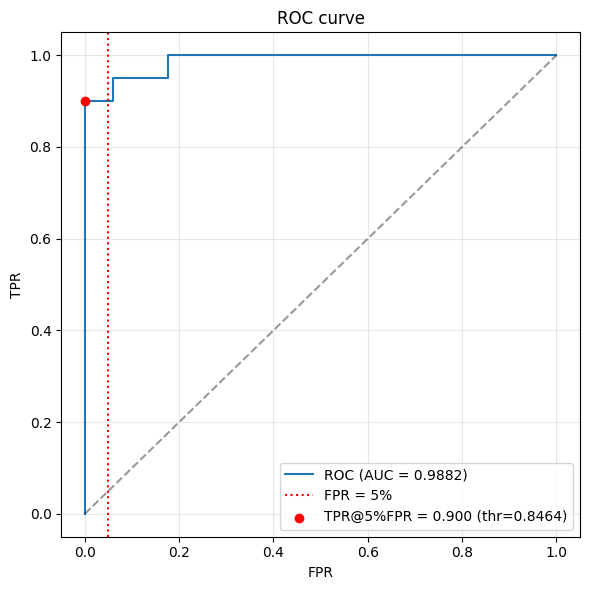

AUROC          : 0.9882
TPR @ 5% FPR   : 0.9000
Threshold      : 0.846411


In [13]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# label : ground truth binaire (0/1) ; target : score continu du détecteur
fpr, tpr, thresholds = roc_curve(label, target)
roc_auc = auc(fpr, tpr)

# Seuil maximisant TPR sous contrainte FPR <= 5%
mask = fpr <= 0.05
idx = np.argmax(tpr[mask])                 # meilleur TPR dans la zone admissible
thr_at_5fpr = thresholds[mask][idx]
tpr_at_5fpr = tpr[mask][idx]
fpr_at_5fpr = fpr[mask][idx]

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"ROC (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.axvline(0.05, color="red", linestyle=":", label="FPR = 5%")
plt.scatter([fpr_at_5fpr], [tpr_at_5fpr], color="red", zorder=5,
            label=f"TPR@5%FPR = {tpr_at_5fpr:.3f} (thr={thr_at_5fpr:.4f})")
plt.xlabel("FPR"); plt.ylabel("TPR")
plt.title("ROC curve"); plt.legend(loc="lower right")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

print(f"AUROC          : {roc_auc:.4f}")
print(f"TPR @ 5% FPR   : {tpr_at_5fpr:.4f}")
print(f"Threshold      : {thr_at_5fpr:.6f}")

In [ ]:
#from src.evaluation.eval_utils import roc_at_fpr_budgets